# Generate Local Authority Half-Hourly Heat Profiles by Technology

This notebook converts GBHeat grid-level half-hourly heating profiles into Local Authority (LA) level heat-demand profiles.

The method uses:

- GBHeat half-hourly grid-level heat-demand profiles
- Atlite grid-cell geometries
- Local Authority boundary geometries
- FES Spatial Heat Model residential heating technology stock

The output is:

- one half-hourly heat-demand profile per Local Authority
- technology-level columns, e.g. ASHP, GSHP, Gas boiler, DH, Hydrogen boiler
- annual LA heat-demand summary
- LA-level heat-demand map

All heat profile values are in:

**kWh per half-hour**

In [1]:
# ============================================================
# Imports
# ============================================================

from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1 import make_axes_locatable

from gbheatmodel.path import path_in_data
from gbheatmodel import FES_heat_supply_data
from gbheatmodel.FES_shapefile_LAs_matching import match_FES_and_shapefile_LAs

from gbheatmodel.LA_heat_profiles import (
    read_hd_profiles_from_folder,
    build_grid_annual_heat_map,
    prepare_fes_stock_index,
    redistribute_grid_heat_to_las,
    build_la_half_hourly_profiles_by_technology,
    save_la_profiles,
)

## Method summary

GBHeat produces domestic heating demand at the Atlite grid-cell level. To generate Local Authority (LA) level heat-demand profiles and maps, the grid cells are spatially overlaid with the 2021 Local Authority boundaries. The heat demand from each grid cell is then redistributed to the intersecting Local Authorities using one of two weighting approaches.

---

### Method 1: FES stock-weighted redistribution

For each grid cell, the heat demand is distributed according to the total FES residential heating stock of the intersecting Local Authorities.

The redistribution factor is

$$
w_{g,l}=
\frac{S_l}
{\sum_{i \in g} S_i}
$$

where

- $S_l$ is the total FES residential heating stock of Local Authority $l$.
- $\sum_{i \in g} S_i$ is the total FES heating stock of all Local Authorities intersecting grid cell $g$.

The heat allocated from grid cell $g$ to Local Authority $l$ is

$$
H_{g,l}=H_g\,w_{g,l}
$$

The total annual heat demand of each Local Authority is then

$$
H_l=\sum_g H_{g,l}
$$

---

### Method 2: FES stock-area weighted redistribution

The second method estimates how much of each Local Authority's heating stock lies inside each grid-LA intersection.

First, the heating stock contained within the intersection is estimated as

$$
\hat{S}_{g,l}
=
S_l
\times
\frac{A_{g,l}}{A_l}
$$

where

- $\hat{S}_{g,l}$ is the estimated heating stock within the grid-LA intersection.
- $S_l$ is the total FES residential heating stock of Local Authority $l$.
- $A_{g,l}$ is the area of the intersection between grid cell $g$ and Local Authority $l$.
- $A_l$ is the total area of Local Authority $l$.

The redistribution factor is then calculated as

$$
w_{g,l}
=
\frac{\hat{S}_{g,l}}
{\sum_{i \in g} \hat{S}_{g,i}}
$$

Finally, the allocated heat demand is

$$
H_{g,l}
=
H_g
\times
w_{g,l}
$$

and the total Local Authority demand is

$$
H_l
=
\sum_g H_{g,l}
$$

---

### Available redistribution methods

| Method | Description |
|---------|-------------|
| `fes_stock` | Redistributes grid heat demand using the total FES residential heating stock of each intersecting Local Authority. |
| `fes_stock_area` | Redistributes grid heat demand using the estimated residential heating stock contained within each grid-LA intersection. |

Both methods conserve the total GBHeat heat demand. The `fes_stock_area` method generally provides a more physically representative redistribution when a Local Authority spans multiple Atlite grid cells.

In [2]:
# ============================================================
# User settings
# ============================================================

weather_year = 2010        # Weather/pattern year
future_year = 2050         # Target future year
FES_year = "2022"          # FES dataset version
FES_scenario = "LW"        # Scenario: LW, CT, ST, FS

# Redistribution method:
# "fes_stock"      = distribute grid heat according to total LA FES stock
# "fes_stock_area" = distribute according to estimated stock inside each grid-LA overlap
method = "fes_stock_area"

save_outputs = True
plot_map = True

output_dir = path_in_data("outputs", "LA_heat_profiles")
Path(output_dir).mkdir(parents=True, exist_ok=True)

In [3]:
# ============================================================
# Load GBHeat grid-level half-hourly heat profiles
# ============================================================

profile_folder = path_in_data(
    "outputs",
    "heating_profiles",
    f"{weather_year}_{FES_year}_{FES_scenario}_{future_year}",
)

print("Loading grid-level heat profiles from:")
print(profile_folder)

profiles = read_hd_profiles_from_folder(profile_folder)

print(f"Loaded {len(profiles)} grid-level profiles.")

Loading grid-level heat profiles from:
C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050
Loaded 738 grid-level profiles.


In [4]:
# ============================================================
# Load Atlite grid geometry and build annual grid heat map
# ============================================================

grid_path = path_in_data("UK_Atlite_Grid_sq.gpkg")
grid_gdf = gpd.read_file(grid_path)

grid_map = build_grid_annual_heat_map(
    profiles=profiles,
    grid_gdf=grid_gdf,
)

print("Grid map columns:")
print(grid_map.columns.tolist())

print("Grid cells with heat demand:", grid_map["Annual_Heat_GWh"].notna().sum())
print("Total grid heat demand [TWh]:", grid_map["Annual_Heat_GWh"].sum() / 1000)

Grid map columns:
['x', 'y', 'geometry', 'Grid_ID', 'Annual_Heat_GWh']
Grid cells with heat demand: 738
Total grid heat demand [TWh]: 222.7662341992331


In [5]:
# ============================================================
# Load Local Authority boundary shapefile
# ============================================================

la_path = path_in_data(
    "LAs_shapefile_2021",
    "LAD_DEC_2021_GB_BFC.shp",
)

la_gdf = gpd.read_file(la_path)

print("Number of Local Authorities:", len(la_gdf))
print(la_gdf[["LAD21CD", "LAD21NM"]].head())

Number of Local Authorities: 363
     LAD21CD               LAD21NM
0  E06000001            Hartlepool
1  E06000002         Middlesbrough
2  E06000003  Redcar and Cleveland
3  E06000004      Stockton-on-Tees
4  E06000005            Darlington


In [6]:
# ============================================================
# Load and prepare FES LA-level heating stock
# ============================================================

fes_raw = FES_heat_supply_data.year_FES_heat_supply(
    year=future_year,
    FES=FES_year,
    scenario=FES_scenario,
)

fes_matched = match_FES_and_shapefile_LAs(
    df=fes_raw,
    future_year=future_year,
    FES=FES_year,
    scenario=FES_scenario,
)

fes_stock_index, tech_cols = prepare_fes_stock_index(fes_matched)

print("Number of matched FES LAs:", len(fes_stock_index))
print("Total FES heating stock:", fes_stock_index["FES_Total_Heat_Stock"].sum())

print("Technology columns:")
for tech in tech_cols:
    print(" -", tech)

Number of matched FES LAs: 363
Total FES heating stock: 32428929.831038244
Technology columns:
 - ASHP
 - BioLPG boiler
 - Biomass boiler
 - Community
 - DH
 - Electric resistive
 - Electric storage
 - GSHP
 - Gas boiler
 - Hybrid (ASHP + BioLPG boiler)
 - Hybrid (ASHP + Electric resistive)
 - Hybrid (ASHP + Hydrogen boiler)
 - Hydrogen boiler
 - Oil boiler
 - stock_proportion ASHP
 - stock_proportion Community
 - stock_proportion DH
 - stock_proportion Electric resistive
 - stock_proportion Electric storage
 - stock_proportion GSHP
 - stock_proportion Gas boiler
 - stock_proportion Oil boiler
 - stock_proportion TotalHPs
 - stock_proportion BioLPG boiler
 - stock_proportion Biomass boiler
 - stock_proportion Hybrid (ASHP + BioLPG boiler)
 - stock_proportion Hybrid (ASHP + Electric resistive)
 - stock_proportion Hybrid (ASHP + Hydrogen boiler)
 - stock_proportion Hydrogen boiler


In [7]:
# ============================================================
# Redistribute annual grid-level heat demand to Local Authorities
# ============================================================

overlay_la, la_demand, la_map = redistribute_grid_heat_to_las(
    grid_map=grid_map,
    la_gdf=la_gdf,
    fes_stock_index=fes_stock_index,
    method=method,
)

grid_total_twh = grid_map["Annual_Heat_GWh"].sum() / 1000
la_total_twh = la_demand["Allocated_Heat_GWh"].sum() / 1000

print("Grid total heat demand [TWh]:", grid_total_twh)
print("LA allocated heat demand [TWh]:", la_total_twh)
print("Difference [TWh]:", grid_total_twh - la_total_twh)

print("Top 20 Local Authorities by annual heat demand:")
display(
    la_demand[["LAD21NM", "Allocated_Heat_GWh"]]
    .sort_values("Allocated_Heat_GWh", ascending=False)
    .head(20)
)

Grid total heat demand [TWh]: 222.7662341992331
LA allocated heat demand [TWh]: 222.7662341992331
Difference [TWh]: 0.0
Top 20 Local Authorities by annual heat demand:


,LAD21NM,Allocated_Heat_GWh
263,Birmingham,3542.537645
273,Leeds,2894.660189
339,Glasgow City,2847.258956
330,City of Edinburgh,2358.692315
44,County Durham,2134.156108
258,Sheffield,2048.520436
242,Manchester,1948.481683
270,Bradford,1937.164872
48,Cornwall,1787.515993
251,Liverpool,1781.100574


In [8]:
# ============================================================
# Generate LA-level half-hourly heat profiles by technology
# ============================================================

la_profiles = build_la_half_hourly_profiles_by_technology(
    profiles=profiles,
    overlay_la=overlay_la,
)

print(f"Generated half-hourly profiles for {len(la_profiles)} Local Authorities.")

# Example LA profile
example_la = next(iter(la_profiles))
print("Example LA code:", example_la)
display(la_profiles[example_la].head())

Generated half-hourly profiles for 363 Local Authorities.
Example LA code: E06000043


,ASHP,GSHP,Gas boiler,Electric storage,Hybrid (ASHP + Electric resistive),Oil boiler,Biomass boiler,BioLPG boiler,Community,Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Hydrogen boiler),DH,Electric resistive,Hydrogen boiler,LAD21NM
2050-01-01 00:00:00,15183.827410,20519.956197,0.020970,5928.762404,6229.026837,0.000003,587.389279,1371.135263,0.536639,371.949155,2756.169315,6916.910669,578.183091,3432.770454,Brighton and Hove
2050-01-01 00:30:00,15419.653628,20917.975705,0.020818,6076.353094,6170.256689,0.000003,581.997869,1358.429533,0.531454,368.556242,2733.087794,6851.441293,572.428160,3403.883007,Brighton and Hove
2050-01-01 01:00:00,15914.497874,21596.164654,0.021455,6276.241800,6351.613294,0.000003,599.189567,1398.487769,0.547005,379.455035,2815.080182,7052.700438,589.082566,3505.919831,Brighton and Hove
2050-01-01 01:30:00,16309.478292,22118.609436,0.022002,6421.292434,6517.167333,0.000003,614.765523,1434.875043,0.561297,389.313128,2887.642724,7236.586370,604.520266,3596.328514,Brighton and Hove
2050-01-01 02:00:00,17075.242945,23041.368321,0.023691,6641.090551,7029.709560,0.000003,662.977343,1547.511643,0.605550,419.825200,3112.093588,7805.896714,652.334355,3875.990564,Brighton and Hove


In [9]:
# ============================================================
# Energy conservation check
# ============================================================

grid_profile_total_twh = sum(
    df.sum(axis=1).sum()
    for df in profiles.values()
) / 1e9

la_profile_total_twh = sum(
    df.drop(columns=["LAD21NM"], errors="ignore").sum().sum()
    for df in la_profiles.values()
) / 1e9

print("Grid half-hourly profile total [TWh]:", grid_profile_total_twh)
print("LA half-hourly profile total [TWh]:", la_profile_total_twh)
print("Difference [TWh]:", grid_profile_total_twh - la_profile_total_twh)

Grid half-hourly profile total [TWh]: 222.76623419923294
LA half-hourly profile total [TWh]: 222.7662341992331
Difference [TWh]: -1.7053025658242404e-13


In [10]:
# ============================================================
# Save LA-level outputs
# ============================================================

if save_outputs:
    saved_profile_folder = save_la_profiles(
        la_profiles=la_profiles,
        output_dir=output_dir,
        FES_year=FES_year,
        scenario=FES_scenario,
        future_year=future_year,
    )

    annual_csv = (
        Path(output_dir)
        / f"LA_annual_heat_demand_{FES_year}_{FES_scenario}_{future_year}_{method}.csv"
    )

    geojson_path = (
        Path(output_dir)
        / f"LA_annual_heat_demand_{FES_year}_{FES_scenario}_{future_year}_{method}.geojson"
    )

    la_demand.to_csv(annual_csv, index=False)
    la_map.to_crs(epsg=4326).to_file(geojson_path, driver="GeoJSON")

    print("Saved LA half-hourly profiles to:")
    print(saved_profile_folder)

    print("Saved annual LA demand CSV:")
    print(annual_csv)

    print("Saved LA demand GeoJSON:")
    print(geojson_path)

Saved LA half-hourly profiles to:
C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\LA_heat_profiles\LA_half_hourly_profiles_2022_LW_2050
Saved annual LA demand CSV:
C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\LA_heat_profiles\LA_annual_heat_demand_2022_LW_2050_fes_stock_area.csv
Saved LA demand GeoJSON:
C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\LA_heat_profiles\LA_annual_heat_demand_2022_LW_2050_fes_stock_area.geojson


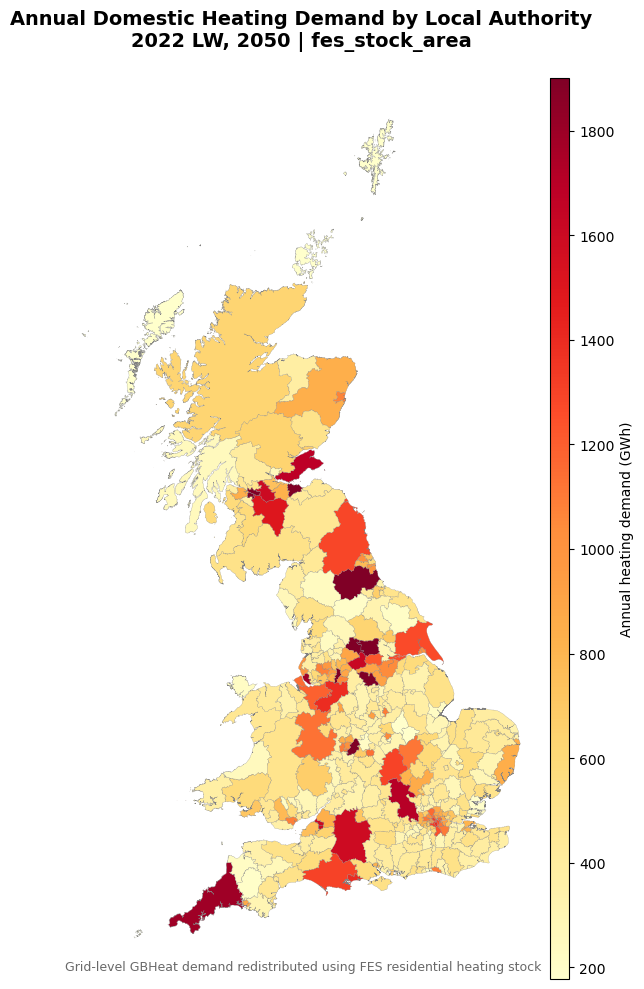

Saved map:
C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\LA_heat_profiles\Figure_LA_annual_heat_demand_2022_LW_2050_fes_stock_area.png


In [11]:
# ============================================================
# Plot LA annual heat-demand map
# ============================================================

if plot_map:
    fig, ax = plt.subplots(figsize=(8, 10))

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.08)

    vmin = la_map["Allocated_Heat_GWh"].quantile(0.02)
    vmax = la_map["Allocated_Heat_GWh"].quantile(0.98)

    la_map.plot(
        column="Allocated_Heat_GWh",
        cmap="YlOrRd",
        linewidth=0.15,
        edgecolor="grey",
        legend=True,
        cax=cax,
        vmin=vmin,
        vmax=vmax,
        missing_kwds={"color": "white"},
        legend_kwds={"label": "Annual heating demand (GWh)"},
        ax=ax,
    )

    ax.set_title(
        f"Annual Domestic Heating Demand by Local Authority\n"
        f"{FES_year} {FES_scenario}, {future_year} | {method}",
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

    ax.text(
        0.01,
        0.01,
        "Grid-level GBHeat demand redistributed using FES residential heating stock",
        transform=ax.transAxes,
        fontsize=9,
        color="dimgray",
    )

    ax.axis("off")
    plt.tight_layout()

    fig_path = (
        Path(output_dir)
        / f"Figure_LA_annual_heat_demand_{FES_year}_{FES_scenario}_{future_year}_{method}.png"
    )

    plt.savefig(fig_path, dpi=600, bbox_inches="tight")
    plt.show()

    print("Saved map:")
    print(fig_path)